Importações, Paleta de Cores e Criando a Variável

## Preparação e carregamento dos dados

Este notebook é uma cópia de trabalho da EDA individual da Aula 11. A análise original foi mantida; as células abaixo preparam os dados para que o notebook possa ser executado de forma reproduzível a partir da raiz do projeto ou da pasta `notebooks`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Localiza a raiz do projeto tanto ao executar da raiz quanto de notebooks/.
RAIZ = Path.cwd()
if not (RAIZ / "data").exists():
    RAIZ = RAIZ.parent

CAMINHO_RAW = RAIZ / "data" / "raw" / "cf_products_with_retailers.csv"
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

# df_original preserva os valores e colunas exatamente como lidos do CSV de entrada.
df_original = pd.read_csv(CAMINHO_RAW)
df_raw = df_original.copy()

print(f"Arquivo carregado: {CAMINHO_RAW.relative_to(RAIZ)}")
print(f"Dimensões originais: {df_original.shape[0]} linhas x {df_original.shape[1]} colunas")


Arquivo carregado: data/raw/cf_products_with_retailers.csv
Dimensões originais: 922 linhas x 11 colunas


In [2]:
print("Colunas:")
print(df_original.columns.tolist())

print("\nTipos originais:")
display(df_original.dtypes.to_frame("dtype"))

print("\nValores ausentes por coluna:")
display(df_original.isna().sum().to_frame("ausentes"))

print(f"\nLinhas duplicadas no arquivo original: {df_original.duplicated().sum()}")


Colunas:
['Unnamed: 0', 'Brand', 'All_vegan', 'Partial_vegan', 'Bad_parent_company', 'Black_owned', 'Ulta', 'Sephora', 'Beauty_Bay', 'Cult_Beauty', 'Nordstrom']

Tipos originais:


,dtype
Unnamed: 0,int64
Brand,object
All_vegan,bool
Partial_vegan,bool
Bad_parent_company,bool
Black_owned,bool
Ulta,int64
Sephora,int64
Beauty_Bay,int64
Cult_Beauty,int64



Valores ausentes por coluna:


,ausentes
Unnamed: 0,0
Brand,0
All_vegan,0
Partial_vegan,0
Bad_parent_company,0
Black_owned,0
Ulta,0
Sephora,0
Beauty_Bay,0
Cult_Beauty,0



Linhas duplicadas no arquivo original: 0


### Avaliação da coluna `Unnamed: 0`

A coluna sem nome costuma aparecer quando um índice do pandas foi exportado para CSV. Ela só será removida se seus valores forem exatamente a sequência de 0 até o número de linhas menos 1. Essa verificação evita descartar uma coluna que possa conter informação real. O CSV de origem permanece intacto.


In [3]:
df = df_original.copy()

if "Unnamed: 0" in df.columns:
    indice_exportado = pd.to_numeric(df["Unnamed: 0"], errors="coerce")
    eh_indice_sequencial = (
        indice_exportado.notna().all()
        and indice_exportado.astype("int64").reset_index(drop=True).equals(
            pd.Series(range(len(df)), dtype="int64")
        )
    )
    print(f"'Unnamed: 0' corresponde a índice exportado sequencial? {eh_indice_sequencial}")
    if eh_indice_sequencial:
        df = df.drop(columns=["Unnamed: 0"])
        print("Coluna removida: era apenas o índice exportado.")
    else:
        print("Coluna preservada: os valores não formam um índice sequencial.")
else:
    print("A coluna 'Unnamed: 0' não está presente.")


'Unnamed: 0' corresponde a índice exportado sequencial? True
Coluna removida: era apenas o índice exportado.


### Padronização e validação dos tipos

No CSV carregado, as quatro características de marca aparecem como booleanas e as cinco colunas de varejistas como inteiros. As conversões abaixo são explícitas e também aceitam os valores textuais correspondentes, caso a origem varie. Em seguida, a validação exige que cada indicador de varejista contenha somente 0 ou 1; valores inesperados interrompem a análise em vez de serem aceitos silenciosamente.


In [4]:
COLUNAS_BOOLEANAS = [
    "All_vegan",
    "Partial_vegan",
    "Bad_parent_company",
    "Black_owned",
]
VAREJISTAS = ["Ulta", "Sephora", "Beauty_Bay", "Cult_Beauty", "Nordstrom"]

for coluna in COLUNAS_BOOLEANAS:
    valores = df[coluna].map({"True": True, "False": False, True: True, False: False})
    if valores.isna().any():
        raise ValueError(f"Valores booleanos inesperados em {coluna}: {df.loc[valores.isna(), coluna].unique()}")
    df[coluna] = valores.astype(bool)

for coluna in VAREJISTAS:
    valores = pd.to_numeric(df[coluna], errors="raise")
    if not valores.isin([0, 1]).all():
        inesperados = valores.loc[~valores.isin([0, 1])].unique()
        raise ValueError(f"Valores diferentes de 0 ou 1 em {coluna}: {inesperados}")
    df[coluna] = valores.astype("int64")

display(df.dtypes.to_frame("dtype tratado"))
print(f"Dimensões após preparação: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("Validação concluída: as cinco colunas de varejistas contêm somente 0 ou 1.")


,dtype tratado
Brand,object
All_vegan,bool
Partial_vegan,bool
Bad_parent_company,bool
Black_owned,bool
Ulta,int64
Sephora,int64
Beauty_Bay,int64
Cult_Beauty,int64
Nordstrom,int64


Dimensões após preparação: 922 linhas x 10 colunas
Validação concluída: as cinco colunas de varejistas contêm somente 0 ou 1.


### Cópia do arquivo original

O CSV de entrada não será sobrescrito. Para registrar o DataFrame tal como foi carregado, esta célula salva uma cópia separada em `data/raw/cf_products_with_retailers_original.csv`. A versão tratada será exportada na última célula, depois das transformações da EDA.


In [5]:
CAMINHO_RAW_COPIA = PASTA_RAW / "cf_products_with_retailers_original.csv"
df_original.to_csv(CAMINHO_RAW_COPIA, index=False)
print(f"Cópia dos dados originais salva em: {CAMINHO_RAW_COPIA.relative_to(RAIZ)}")


Cópia dos dados originais salva em: data/raw/cf_products_with_retailers_original.csv


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Cores distintas para os valores da variável; nenhuma cor implica certificação.
sns.set_theme(style="whitegrid")
COR_NAO_MARCADO = "#4c78a8"
COR_MARCADO = "#f58518"

VAREJISTAS = ["Ulta", "Sephora", "Beauty_Bay", "Cult_Beauty", "Nordstrom"]

# Variável agregada (total de redes varejistas)
df["total_retailers"] = df[VAREJISTAS].sum(axis=1)


Diagnóstico de Qualidade dos Dados e Resumo Estatístico

In [7]:
print("--- Verificação de Duplicadas e Nulos ---")
print(f"Total de linhas duplicadas: {df.duplicated().sum()}")
print(df.isna().sum())

print("\n--- Resumo Estatístico Inicial ---")
df[VAREJISTAS + ["total_retailers"]].describe().round(3)

--- Verificação de Duplicadas e Nulos ---
Total de linhas duplicadas: 0
Brand                 0
All_vegan             0
Partial_vegan         0
Bad_parent_company    0
Black_owned           0
Ulta                  0
Sephora               0
Beauty_Bay            0
Cult_Beauty           0
Nordstrom             0
total_retailers       0
dtype: int64

--- Resumo Estatístico Inicial ---


,Ulta,Sephora,Beauty_Bay,Cult_Beauty,Nordstrom,total_retailers
count,922.000,922.0,922.000,922.000,922.000,922.000
mean,0.153,0.1,0.043,0.052,0.055,0.403
std,0.360,0.3,0.204,0.222,0.229,0.865
min,0.000,0.0,0.000,0.000,0.000,0.000
25%,0.000,0.0,0.000,0.000,0.000,0.000
50%,0.000,0.0,0.000,0.000,0.000,0.000
75%,0.000,0.0,0.000,0.000,0.000,0.000
max,1.000,1.0,1.000,1.000,1.000,5.000


## Distribuição, valores extremos e transformação logarítmica

`total_retailers` é uma contagem discreta entre 0 e 5. Como a distribuição tem forte concentração em zero, Q1 e Q3 podem ser iguais a zero; nesse caso, o limite superior pelo IQR também fica em zero e o método classifica toda marca com presença em alguma rede como outlier. Essa regra é pouco informativa para esta variável e não será usada para rotular nem remover marcas. A tabela e o gráfico a seguir descrevem diretamente a frequência de cada contagem.

A transformação `log1p` é mantida como comparação exploratória da assimetria. Ela não altera a variável original nem remove observações.


In [8]:
frequencias_rede = df["total_retailers"].value_counts().reindex(range(6), fill_value=0)
tabela_frequencias = pd.DataFrame(
    {
        "Marcas": frequencias_rede,
        "Proporção (%)": (frequencias_rede / len(df) * 100).round(1),
    }
)
tabela_frequencias.index.name = "Número de redes varejistas"
display(tabela_frequencias)

# Comparação exploratória: a variável transformada é mantida no dataset exportado.
df["total_retailers_log"] = np.log1p(df["total_retailers"])
comp = pd.DataFrame(
    {
        "Original": [
            df["total_retailers"].mean(),
            df["total_retailers"].median(),
            df["total_retailers"].skew(),
            df["total_retailers"].kurtosis(),
        ],
        "Log(1+x)": [
            df["total_retailers_log"].mean(),
            df["total_retailers_log"].median(),
            df["total_retailers_log"].skew(),
            df["total_retailers_log"].kurtosis(),
        ],
    },
    index=["Média", "Mediana", "Assimetria (Skew)", "Curtose"],
).round(3)
print("\n--- Comparação exploratória antes e depois de log1p ---")
display(comp)


,Marcas,Proporção (%)
Número de redes varejistas,,
0,697,75.6
1,140,15.2
2,44,4.8
3,24,2.6
4,13,1.4
5,4,0.4



--- Comparação exploratória antes e depois de log1p ---


,Original,Log(1+x)
Média,0.403,0.224
Mediana,0.000,0.000
Assimetria (Skew),2.646,1.748
Curtose,7.456,1.998


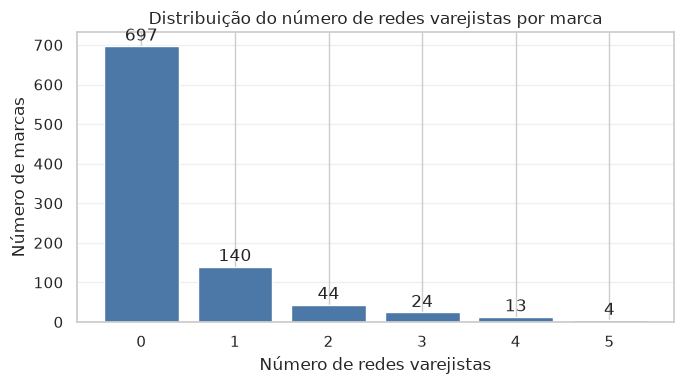

Interpretação descritiva: 697 de 922 marcas (75.6%) não têm presença registrada nas cinco redes; 225 têm presença em pelo menos uma. O gráfico descreve esta base e não implica causalidade nem representa necessariamente todo o mercado.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(frequencias_rede.index.astype(str), frequencias_rede.values, color="#4c78a8")
ax.set_title("Distribuição do número de redes varejistas por marca")
ax.set_xlabel("Número de redes varejistas")
ax.set_ylabel("Número de marcas")
ax.set_xticks(range(6), labels=[str(valor) for valor in range(6)])
ax.grid(axis="y", alpha=0.3)
for posicao, frequencia in enumerate(frequencias_rede.values):
    ax.annotate(str(frequencia), (posicao, frequencia), xytext=(0, 4), textcoords="offset points", ha="center")
plt.tight_layout()
plt.show()

marcas_zero = int(frequencias_rede.loc[0])
percentual_zero = marcas_zero / len(df) * 100
marcas_com_presenca = len(df) - marcas_zero
print(
    f"Interpretação descritiva: {marcas_zero} de {len(df)} marcas "
    f"({percentual_zero:.1f}%) não têm presença registrada nas cinco redes; "
    f"{marcas_com_presenca} têm presença em pelo menos uma. "
    "O gráfico descreve esta base e não implica causalidade nem representa necessariamente todo o mercado."
)


Matriz de Correlação entre Varejistas

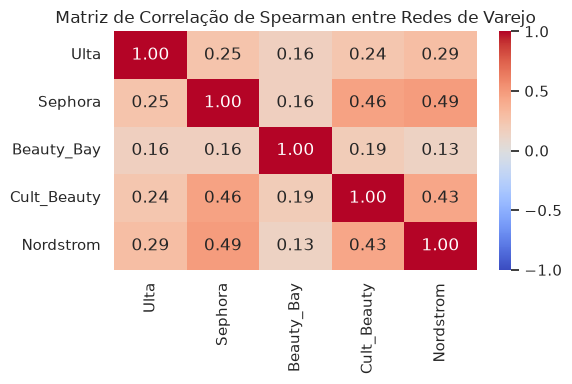

In [ ]:
plt.figure(figsize=(6, 4))
sns.heatmap(
    df[VAREJISTAS].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
plt.title("Matriz de Correlação de Spearman entre Redes de Varejo")
plt.tight_layout()
plt.show()

### Presença em varejistas por valor de `Bad_parent_company`

`False` significa que a característica não está marcada como verdadeira nesta coluna; isso, por si só, não comprova certificação cruelty-free. O gráfico compara apenas os grupos codificados na variável.


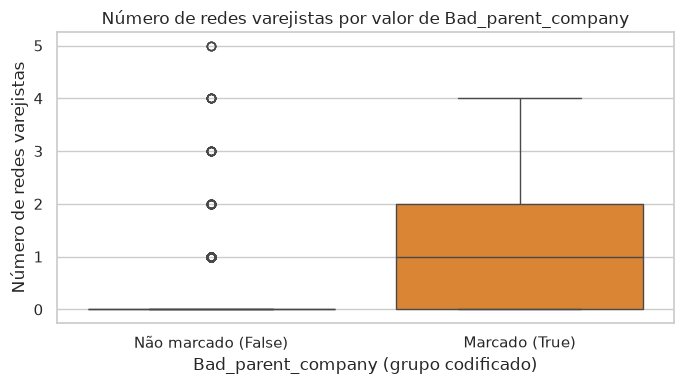

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
grupo_empresa_mae = df["Bad_parent_company"].map(
    {False: "Não marcado (False)", True: "Marcado (True)"}
)
ordem_grupos = ["Não marcado (False)", "Marcado (True)"]
paleta_grupos = {"Não marcado (False)": COR_NAO_MARCADO, "Marcado (True)": COR_MARCADO}
sns.boxplot(
    data=df.assign(grupo_empresa_mae=grupo_empresa_mae),
    x="grupo_empresa_mae",
    y="total_retailers",
    order=ordem_grupos,
    palette=paleta_grupos,
    hue="grupo_empresa_mae",
    hue_order=ordem_grupos,
    legend=False,
    ax=ax,
)
ax.set_title("Número de redes varejistas por valor de Bad_parent_company")
ax.set_xlabel("Bad_parent_company (grupo codificado)")
ax.set_ylabel("Número de redes varejistas")
plt.tight_layout()
plt.show()


### Cruzamento de características da marca e da empresa-mãe


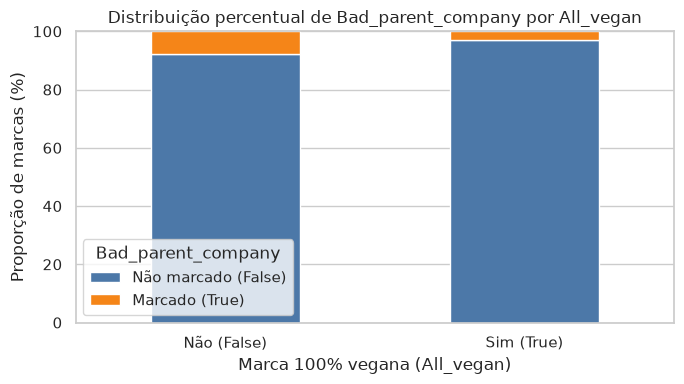

In [ ]:
# Proporção de cada valor de Bad_parent_company dentro de cada categoria de All_vegan.
proporcoes_veganismo = pd.crosstab(
    df["All_vegan"],
    df["Bad_parent_company"],
    normalize="index",
).reindex(index=[False, True], columns=[False, True], fill_value=0)
proporcoes_veganismo.index = ["Não (False)", "Sim (True)"]
proporcoes_veganismo.columns = ["Não marcado (False)", "Marcado (True)"]

ax = (proporcoes_veganismo * 100).plot(
    kind="bar",
    stacked=True,
    figsize=(7, 4),
    color=[COR_NAO_MARCADO, COR_MARCADO],
)
ax.set_title("Distribuição percentual de Bad_parent_company por All_vegan")
ax.set_xlabel("Marca 100% vegana (All_vegan)")
ax.set_ylabel("Proporção de marcas (%)")
ax.set_ylim(0, 100)
ax.set_xticklabels(proporcoes_veganismo.index, rotation=0)
ax.legend(title="Bad_parent_company")
plt.tight_layout()
plt.show()


Declaração de Uso de IA: A Inteligência Artificial foi utilizada apenas como suporte para organizar os códigos em Python, gerar os gráficos e estruturar os textos de explicação do trabalho.

## Exportação do dataset tratado

O arquivo exportado preserva todas as marcas. A classificação por IQR não é usada, nenhuma observação é removida e a contagem de linhas é conferida após a exportação.


In [13]:
CAMINHO_CLEAN = PASTA_CLEAN / "cf_products_with_retailers.csv"
df.to_csv(CAMINHO_CLEAN, index=False)
print(f"Dataset tratado salvo em: {CAMINHO_CLEAN.relative_to(RAIZ)}")
print(f"Dimensões exportadas: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Observações preservadas: {len(df)}")


Dataset tratado salvo em: data/clean/cf_products_with_retailers.csv
Dimensões exportadas: 922 linhas x 12 colunas
Observações preservadas: 922
